In [23]:
"""
Figure generation for training_dynamics for the simplicity bias 
"""

import sys
sys.path.append('..')
from setup import *
from R2D3 import *
from pathlib import Path
from torch.utils.data import DataLoader
from Tasks import cycling
from train import TrainingLogger
from TrainingDynamics.TrainingDynamicsAnalyzer import DynamicsAnalyzer
from TrainingDynamics.simplicity_bias import * 

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [24]:
# just get them from here, instead of always porting from default_params() 
# -> bad habit

(_, 
model_params,
task_params,
training_params
) = load_rnn("saved_models/g_run/run_0")

cycles = Task.load_task("Cycling", task_params)

x_all, y_all, mask_all = next(iter(
    DataLoader(
        cycles,
        batch_size=len(cycles),
        shuffle=False
    )
))

ROOT = Path("saved_models/log_g_final_3")
model_dirs = [p for p in ROOT.iterdir() if p.is_dir()]
test_dir = model_dirs[-25]
logger_path = test_dir / "logger.pt"
logger = TrainingLogger.load(logger_path)
model, *_ = load_rnn(test_dir)
epochs = np.asarray(logger.epochs)
param_history = logger["params"]

In [25]:
# Sanity check

analyzer = DynamicsAnalyzer(logger)
print("epochs:", A.epochs.shape)
print("params:", len(A.params))
print("W_rec:", A.W_rec.shape)
print("dW_rec:", A.dW_rec.shape)
print("U:", A.rec_U.shape)
print("S:", A.rec_singular_values.shape)
print("V:", A.rec_V.shape)

epochs: (192,)
params: 192
W_rec: (192, 256, 256)
dW_rec: (192, 256, 256)
U: (192, 256, 256)
S: (192, 256)
V: (192, 256, 256)


In [74]:
# add all relevant properties and send to them to the cache

analyzer.add(
    "full_task_gradients_and_losses",
    lambda _: compute_full_task_gradients_and_losses(
        params=analyzer.params,
        model=model,
        task=cycles,
        loss_func=mse,
        init_hidden=None
    ),
    overwrite=True
)

analyzer.add(
    "effective_rank",
    lambda _: compute_effective_ranks(
        analyzer=analyzer
    ),
    overwrite=True
)


analyzer.add(
    "stage_wise_recurrent_gradients",
    lambda _: compute_stagewise_gradient_energy(
        analyzer=analyzer
    ),
    overwrite=True
)

analyzer.add(
    "stage_wise_I0_gradients",
    lambda _: compute_stagewise_IO_changes(
        analyzer=analyzer
    ),
    overwrite=True
)

for callable in analyzer._callables:
    analyzer.execute(callable, force=True)


In [77]:
analyzer["stage_wise_I0_gradients"].keys()

dict_keys(['dWin_cumulative', 'dWin_marginal', 'dWout_cumulative', 'dWout_marginal'])

In [54]:
# this should also be added to the analyzer
learning_events = detect_learning_windows(analyzer)
centres = np.asarray(
        [
        event["center_idx"] 
        for event in learning_events["events"]
        ]
    )

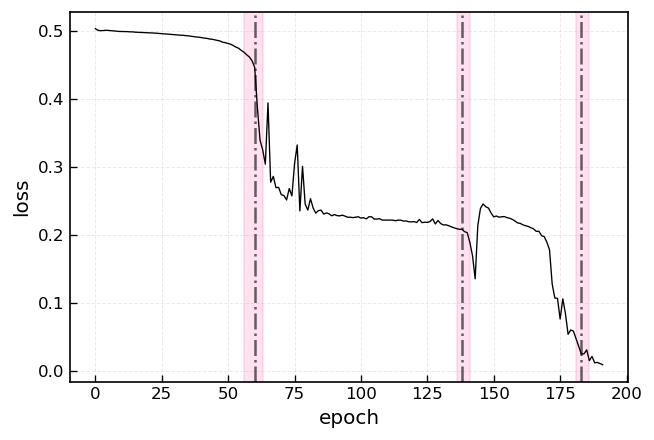

In [106]:
losses = analyzer["full_task_gradients_and_losses"]["losses"]

fig = plt.figure(figsize=(6,4))
ax = fig.add_subplot(111)
ax.plot(losses, c="black", linewidth=.8)
ax.set_xlabel("epoch")
ax.set_ylabel("loss")

for event in learning_events["events"]:
        ax.axvline(event["center_idx"],
               color="black",
               linewidth=1.5,
               alpha=.6,
               linestyle="-.")
        
        ax.axvspan(event["start_idx"],
                   event["end_idx"],
                   color="hotpink",
                   alpha=.2)

# plt.savefig("Figures/Figures_4/learning_windows_loss.png")   
plt.show()

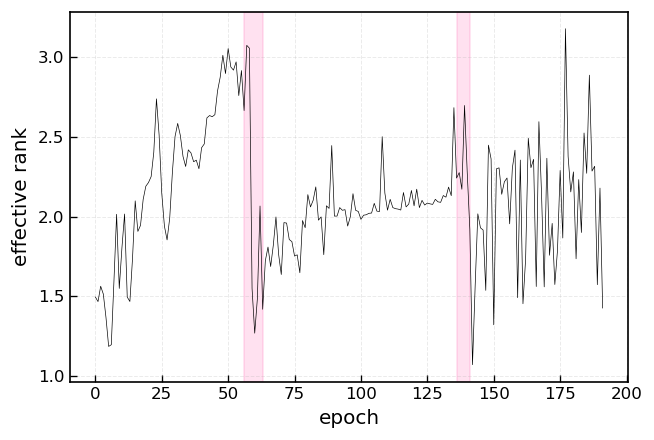

In [125]:
# track gradient effective rank 
effective_rank = analyzer["effective_rank"]

fig = plt.figure(figsize=(6,4))
ax = fig.add_subplot(111)
ax.plot(effective_rank,
        c="black",
        linewidth=.4)

ax.set_ylabel("effective rank")
ax.set_xlabel("epoch")

start = 0

for idx, event in enumerate(learning_events["events"][:-1]):
        ax.axvspan(event["start_idx"],
                event["end_idx"],
                color="hotpink",
                alpha=.2)

        """
        ax.plot(range(
                        start,
                        event["start_idx"]
                ),
                np.linspace(
                        effective_rank[start],
                        effective_rank[event["start_idx"]],
                        event["start_idx"] - start      
                )
                )
        
        start = event["end_idx"]
        """
plt.savefig("Figures/Figures_4/effective_r.png")
plt.show()

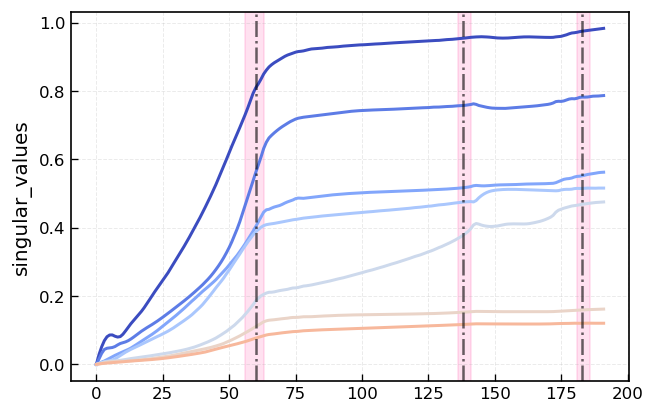

In [149]:
# track weight change matrix 

fig = plt.figure(figsize=(6,4))
ax = fig.add_subplot(111)
ax.plot(analyzer.rec_singular_values[:,:MAX_RANK])
ax.set_ylabel("singular_values")

for event in learning_events["events"]:
        ax.axvline(event["center_idx"],
               color="black",
               linewidth=1.5,
               alpha=.6,
               linestyle="-.")
        
        ax.axvspan(event["start_idx"],
                   event["end_idx"],
                   color="hotpink",
                   alpha=.2)
        


plt.savefig("Figures/Figures_4/weight_change_singular_values_with_learning_windows.png")
plt.show()

0.7356776878293302


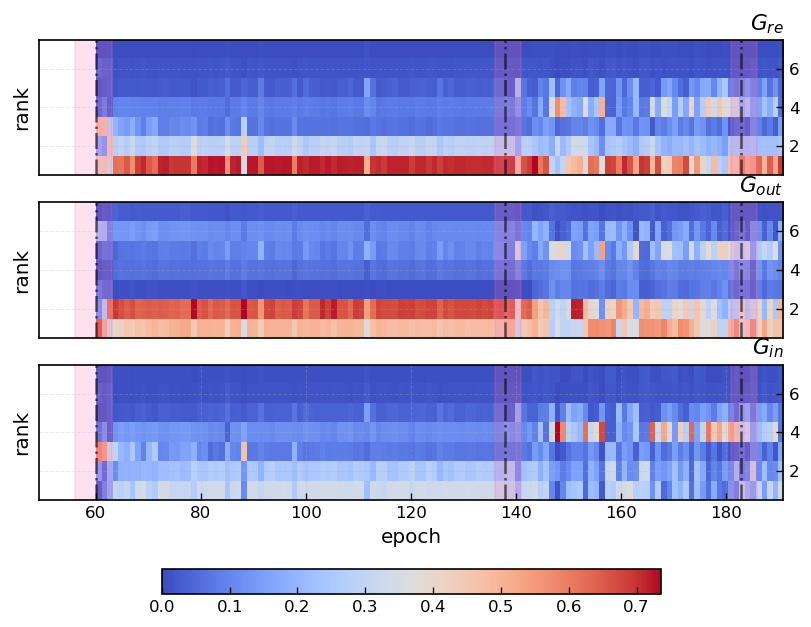

In [148]:
# let's just plot this for starters and see what happens
G_marginal = analyzer["stage_wise_recurrent_gradients"]["G_marginal"]
G_marginal_out = analyzer["stage_wise_recurrent_gradients"]["G_marginal_out"]
G_marginal_in = analyzer["stage_wise_recurrent_gradients"]["G_marginal_in"]

fig, axs = plt.subplots(3, 1, figsize=(8,6))

im = axs[0].imshow(
        G_marginal.T,
        aspect="auto",
        origin="lower",
        extent=[
            centres[0],
            epochs[-1],
            .5,
            MAX_RANK + .5
        ],
        vmin=0,
        vmax=np.nanmax(
            G_marginal
        )
    )

axs[0].set_title(r"$G_{re}$", loc="right")
axs[0].set_xticks([])

im = axs[1].imshow(
        G_marginal_out.T,
        aspect="auto",
        origin="lower",
        extent=[
            centres[0],
            epochs[-1],
            .5,
            MAX_RANK + .5
        ],
        vmin=0,
        vmax=np.nanmax(
            G_marginal_out
        )
    )
axs[1].set_title(r"$G_{out}$", loc="right")
axs[1].set_xticks([])

im = axs[2].imshow(
        G_marginal_in.T,
        aspect="auto",
        origin="lower",
        extent=[
            centres[0],
            epochs[-1],
            .5,
            MAX_RANK + .5
        ],
        vmin=0,
        vmax=np.nanmax(
            G_marginal_in
        )
    )

axs[2].set_title(r"$G_{in}$", loc="right")
axs[2].set_xlabel("epoch")

for ax in axs:
    ax.yaxis.tick_right()

    for event in learning_events["events"]:
        ax.axvline(event["center_idx"],
               color="black",
               linewidth=1.5,
               alpha=.6,
               linestyle="-.")
        
        ax.axvspan(event["start_idx"],
                   event["end_idx"],
                   color="hotpink",
                   alpha=.2)
        
        ax.set_ylabel("rank",
                      rotation=90,
                      labelpad=5)
        
vmax = np.max([np.nanmax(G) for G in [
    G_marginal, G_marginal_out, G_marginal_in
]])

print(vmax)


# After plotting all three:
fig.colorbar(im, ax=axs, location="bottom", pad=0.125, fraction=.045)

plt.savefig("Figures/Figures_4/grads_with_colorbar.png")
plt.show()

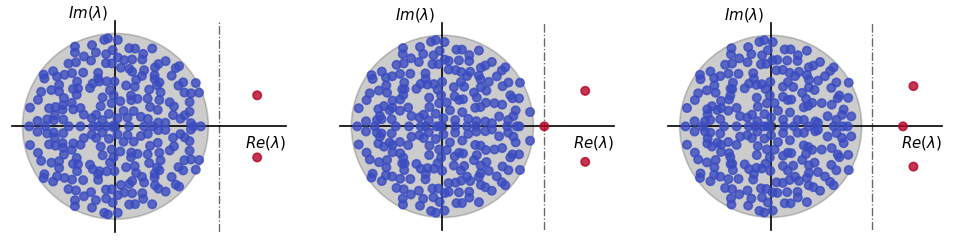

In [60]:
# track eigenvalue spectrum over the windows
fig, axs = plt.subplots(1, 3, figsize=(10, 6))

for idx, event in enumerate(learning_events["events"]):
    
    # plot structure at the end of learning window
    plot_spectrum(model, w_rec=False, mat=A.W_rec[event["end_idx"]], ax=axs[idx])

# plt.savefig("Figures/Figures_4/learning_stage_eigenvalue_spectrum.png")
plt.show()

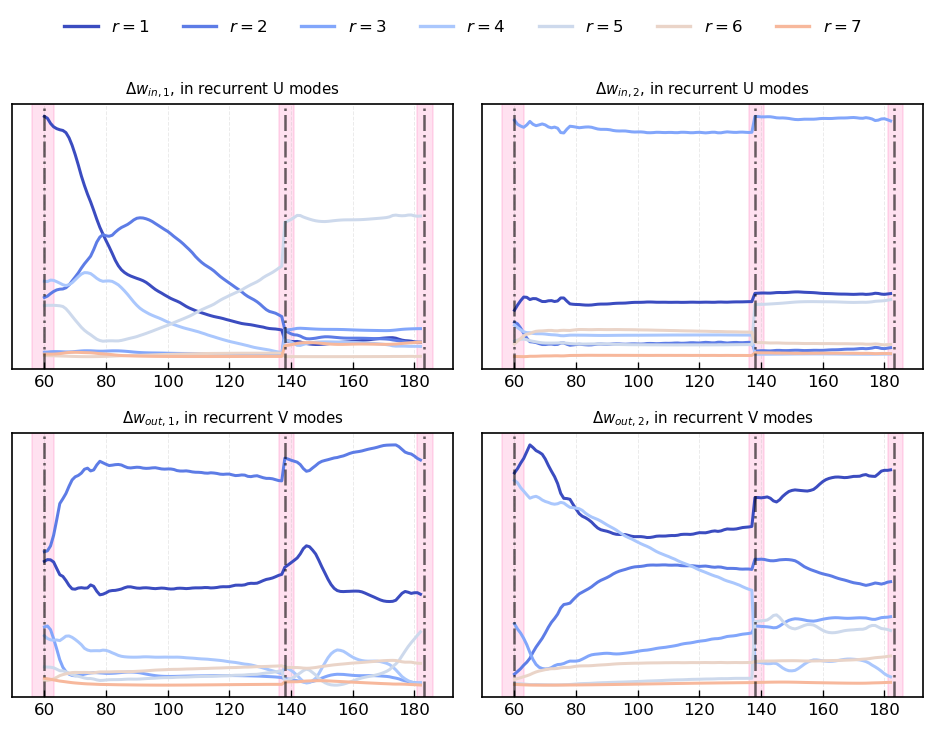

In [126]:
dWin_marginal = analyzer["stage_wise_I0_gradients"]["dWin_marginal"]
dWout_marginal = analyzer["stage_wise_I0_gradients"]["dWout_marginal"]

from matplotlib.lines import Line2D
colors = get_colors(num_colors=MAX_RANK + 2) # why? This is random. 

fig, axs = plt.subplots(2, 2, figsize=(8, 6))
xvals = range(centres[0], centres[0] + dWin_marginal.shape[0])
axs[0,0].plot(xvals, dWin_marginal[:,0,:])
axs[0,1].plot(xvals, dWin_marginal[:,1,:])
axs[1,0].plot(xvals, dWout_marginal[:,0,:])
axs[1,1].plot(xvals, dWout_marginal[:,1,:])

axs[0,0].set_title(
    r"$\Delta w_{in, 1}$, in recurrent U modes",
    fontsize=9
    )
axs[0,1].set_title(
    r"$\Delta w_{in, 2}$, in recurrent U modes",
    fontsize=9
    )
axs[1,0].set_title(
    r"$\Delta w_{out, 1}$, in recurrent V modes",
    fontsize=9
    )
axs[1,1].set_title(
    r"$\Delta w_{out, 2}$, in recurrent V modes",
    fontsize=9
    )

for ax in fig.axes:

    for event in learning_events["events"]:
        ax.axvline(event["center_idx"],
               color="black",
               linewidth=1.5,
               alpha=.6,
               linestyle="-.")
        
        ax.axvspan(event["start_idx"],
                   event["end_idx"],
                   color="hotpink",
                   alpha=.2)
        
        ax.set_yticks([])

handles = [
    Line2D(
        [0], [0],
        color=colors[r],
        lw=2,
        label=f"$r={r+1}$"
    )
    for r in range(MAX_RANK)
]

fig.legend(
    handles=handles,
    loc="upper center",
    ncol=MAX_RANK,
    frameon=False,
    bbox_to_anchor=(0.5, 1.02)
)


fig.tight_layout(
    rect=[0, 0, 1, .94]
)
plt.savefig("Figures/Figures_4/IO.png")
plt.show()


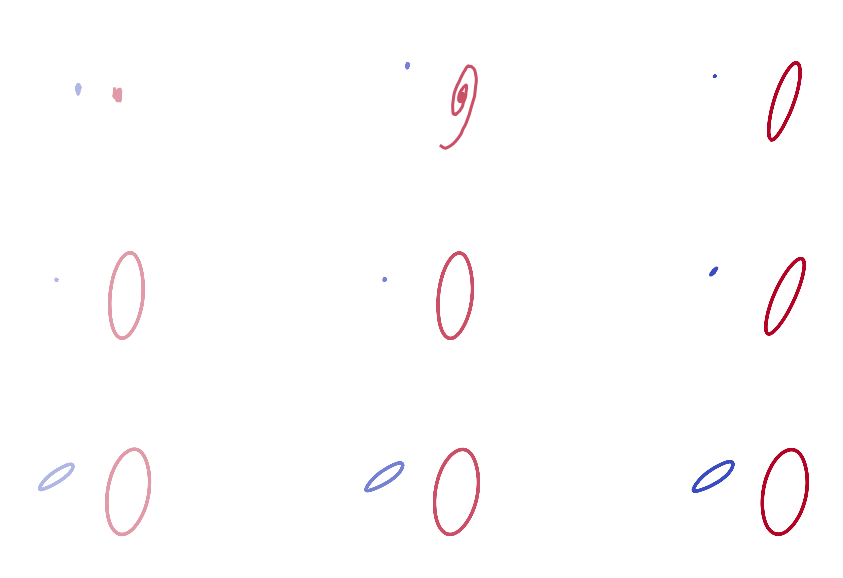

In [89]:
# let's also get the dynamics at each of these points (do a PCA here?):
from sklearn.decomposition import PCA 
rates = analyzer["full_task_gradients_and_losses"]["rates"]
trnst = 50
with plotstyle.context("inputs", 2):

    fig = plt.figure(figsize=(10, 6))
    counter = 0
    for idx, event in enumerate(learning_events["events"]):

        ax = fig.add_subplot(3, 3, counter + 1, projection="3d")
        pca = PCA(n_components=3)
        rates_ = rates[event["start_idx"]].reshape(-1, 256)
        pca.fit(rates_)
        rates_ = pca.transform(rates_)
        rates_ = rates_.reshape(2, 200, -1)
        ax = fig.add_subplot(3, 3, counter + 1, projection="3d")
        for i in range(rates_.shape[0]):
            ax.plot(rates_[i, trnst:, 0],
                    rates_[i, trnst:, 1],
                    rates_[i, trnst:, 2],
                    alpha=.4)
            
        counter += 1
            
        pca = PCA(n_components=3)
        rates_ = rates[event["center_idx"]].reshape(-1, 256)
        pca.fit(rates_)
        rates_ = pca.transform(rates_)
        rates_ = rates_.reshape(2, 200, -1)
        ax = fig.add_subplot(3, 3, counter + 1, projection="3d")
        for i in range(rates_.shape[0]):
            ax.plot(rates_[i, trnst:, 0],
                    rates_[i, trnst:, 1],
                    rates_[i, trnst:, 2],
                    alpha=.7 
                    )
        
        counter += 1
            
        pca = PCA(n_components=3)
        rates_ = rates[event["end_idx"]].reshape(-1, 256)
        pca.fit(rates_)
        rates_ = pca.transform(rates_)
        rates_ = rates_.reshape(2, 200, -1)
        ax = fig.add_subplot(3, 3, counter + 1, projection="3d")
        for i in range(rates_.shape[0]):
            ax.plot(rates_[i, trnst:, 0],
                    rates_[i, trnst:, 1],
                    rates_[i, trnst:, 2],
                    alpha=1
                    )
            
        counter += 1

    for ax in fig.axes:
            
        ax.set_xticklabels([])
        ax.set_yticklabels([])
        ax.set_zticklabels([])
        ax.grid(False)
        ax.axis('off')

# plt.savefig("Figures/Figures_4/stagewise_pca_dynamics.png")
plt.savefig("Figures/Figures_4/stagewise_pca_dynamics_axis_off_start_middle_end.png")
plt.show()

